# Decision Tree Classification on PCA-Transformed Data

**Project:** PCA-based classification benchmark  
**Model:** Decision Tree Classifier  
**Training file:** `preprocessed_train_pca.csv`  
**Test file:** `preprocessed_test_pca.csv` (update the path below if your filename is different)

## Notebook objectives
By the end of this notebook, we will:
1. Load and inspect the PCA training data.
2. Validate the target and PCA feature columns.
3. Check missing values, duplicates, class balance, and data types.
4. Create a stratified train/validation split.
5. Train a baseline Decision Tree.
6. Tune hyperparameters using cross-validation.
7. Evaluate the selected model with classification metrics and plots.
8. Inspect feature importance and visualize a shallow version of the tree.
9. Evaluate the final model on your separate PCA test dataset, if it is available.
10. Save the trained model and evaluation artifacts.

> **Important:** This notebook assumes the PCA transformation has already been performed and the columns `PC01`, `PC02`, … are the transformed features. A Decision Tree does not require feature scaling. If PCA was fitted before splitting the original data, information from validation/test data may have influenced the PCA transformation. For a leakage-safe experiment, fit PCA on the training split only and transform validation/test data using that fitted PCA object.

## 1. Import libraries

We use:
- **pandas / NumPy** to load and inspect data.
- **scikit-learn** to split data, train the Decision Tree, tune hyperparameters, and calculate metrics.
- **matplotlib / seaborn** to visualize performance.
- **joblib** to save the trained pipeline/model.

If an import fails, install the missing package in the same Python environment used by Jupyter.

In [2]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Set the file paths

Place both CSV files in the same folder as this notebook, or replace the paths below with their full paths.

The uploaded training file is named `preprocessed_train_pca.csv`. The test file is expected to be named `preprocessed_test_pca.csv`; change `TEST_PATH` if yours has a different name.

In [3]:
TRAIN_PATH = Path("preprocessed_train_pca.csv")
TEST_PATH = Path("preprocessed_test_pca.csv")  # Change this if needed

if not TRAIN_PATH.exists():
    raise FileNotFoundError(
        f"Training file not found: {TRAIN_PATH.resolve()}\n"
        "Move the CSV next to this notebook or update TRAIN_PATH."
    )

train_df = pd.read_csv(TRAIN_PATH)

print("Training data loaded.")
print("Shape:", train_df.shape)
display(train_df.head())

Training data loaded.
Shape: (47875, 26)


,PC01,PC02,PC03,PC04,PC05,PC06,PC07,PC08,PC09,PC10,...,PC17,PC18,PC19,PC20,PC21,PC22,PC23,PC24,PC25,target
0,-4.603128,1.678861,-1.419249,-1.099112,-0.967836,0.187391,0.095995,3.000505,0.446165,0.621242,...,0.124783,-0.245364,0.383272,0.417093,-0.487010,0.919774,-0.115191,-0.419539,-0.655163,0
1,1.777175,10.458797,-1.632330,0.115482,1.847320,-0.461765,-0.568795,2.357430,1.434092,-2.175945,...,0.550571,-0.415791,0.757650,-0.529878,-0.563746,-0.074933,-0.547493,1.254218,0.163475,1
2,5.566793,0.931760,-1.902135,4.107839,-0.810134,0.808116,2.565517,-2.842359,0.895604,2.708044,...,-1.598353,-1.051824,-1.210126,-1.659753,-0.250925,0.266706,0.430985,-0.184668,-0.269085,1
3,0.587602,7.742090,-1.166531,1.488328,2.433178,-0.530288,-0.462300,1.469684,1.280535,-2.950102,...,-1.005752,1.322223,0.025105,-1.082447,-0.849874,0.573380,-0.731772,0.120409,-0.051969,1
4,-4.448724,1.010137,-0.602875,-0.632315,-0.613366,0.262325,0.426372,3.015591,0.507760,0.768383,...,-0.531365,0.306382,0.083267,0.382225,-0.274019,0.736406,0.318651,-0.622345,-0.832435,0


## 3. Understand the dataset

Check the number of rows and columns, column names, data types, and summary statistics. PCA columns are numerical components. The target column contains the class label that the model must predict.

In [4]:
print("Dataset shape:", train_df.shape)
print("\nColumn names:")
print(train_df.columns.tolist())

print("\nData types:")
display(train_df.dtypes.to_frame("dtype"))

print("\nSummary statistics:")
display(train_df.describe().T)

print("\nFirst five rows:")
display(train_df.head())

Dataset shape: (47875, 26)

Column names:
['PC01', 'PC02', 'PC03', 'PC04', 'PC05', 'PC06', 'PC07', 'PC08', 'PC09', 'PC10', 'PC11', 'PC12', 'PC13', 'PC14', 'PC15', 'PC16', 'PC17', 'PC18', 'PC19', 'PC20', 'PC21', 'PC22', 'PC23', 'PC24', 'PC25', 'target']

Data types:


,dtype
PC01,float64
PC02,float64
PC03,float64
PC04,float64
PC05,float64
PC06,float64
PC07,float64
PC08,float64
PC09,float64
PC10,float64



Summary statistics:


,count,mean,std,min,25%,50%,75%,max
PC01,47875.0,1.187330e-17,4.431768,-5.996059,-3.727373,-0.644873,2.351022,21.473947
PC02,47875.0,-2.178750e-16,3.921019,-11.502637,-2.562036,-0.558209,1.758884,10.946288
PC03,47875.0,7.598911e-17,2.507489,-7.452233,-1.656533,-0.062070,1.707945,14.150949
PC04,47875.0,2.208434e-16,2.283419,-13.298291,-1.240954,0.144572,1.559380,7.954430
PC05,47875.0,4.749320e-18,2.161351,-8.068477,-1.160920,-0.131266,0.987102,10.345227
PC06,47875.0,5.817916e-17,2.002008,-8.156803,-0.795688,0.025445,0.856775,15.704809
PC07,47875.0,-1.496036e-16,1.813665,-6.231141,-1.039307,-0.275772,0.648583,9.980093
PC08,47875.0,-4.749320e-17,1.670056,-7.971848,-1.041972,-0.062527,1.212080,6.744156
PC09,47875.0,-7.598911e-17,1.569014,-5.785595,-1.059043,-0.209360,0.961066,7.636538
PC10,47875.0,1.899728e-17,1.478638,-6.327616,-0.879524,0.006555,0.862968,8.754879



First five rows:


,PC01,PC02,PC03,PC04,PC05,PC06,PC07,PC08,PC09,PC10,...,PC17,PC18,PC19,PC20,PC21,PC22,PC23,PC24,PC25,target
0,-4.603128,1.678861,-1.419249,-1.099112,-0.967836,0.187391,0.095995,3.000505,0.446165,0.621242,...,0.124783,-0.245364,0.383272,0.417093,-0.487010,0.919774,-0.115191,-0.419539,-0.655163,0
1,1.777175,10.458797,-1.632330,0.115482,1.847320,-0.461765,-0.568795,2.357430,1.434092,-2.175945,...,0.550571,-0.415791,0.757650,-0.529878,-0.563746,-0.074933,-0.547493,1.254218,0.163475,1
2,5.566793,0.931760,-1.902135,4.107839,-0.810134,0.808116,2.565517,-2.842359,0.895604,2.708044,...,-1.598353,-1.051824,-1.210126,-1.659753,-0.250925,0.266706,0.430985,-0.184668,-0.269085,1
3,0.587602,7.742090,-1.166531,1.488328,2.433178,-0.530288,-0.462300,1.469684,1.280535,-2.950102,...,-1.005752,1.322223,0.025105,-1.082447,-0.849874,0.573380,-0.731772,0.120409,-0.051969,1
4,-4.448724,1.010137,-0.602875,-0.632315,-0.613366,0.262325,0.426372,3.015591,0.507760,0.768383,...,-0.531365,0.306382,0.083267,0.382225,-0.274019,0.736406,0.318651,-0.622345,-0.832435,0


## 4. Identify the target and PCA features

The uploaded training file uses `target` as the label column. The code checks for it explicitly so a misspelled or differently named target is caught early.

All other columns are treated as PCA features. Do not include the target among the input features.

In [5]:
TARGET_COLUMN = "target"

if TARGET_COLUMN not in train_df.columns:
    raise ValueError(
        f"Expected target column '{TARGET_COLUMN}' was not found. "
        f"Available columns: {train_df.columns.tolist()}"
    )

X = train_df.drop(columns=[TARGET_COLUMN]).copy()
y = train_df[TARGET_COLUMN].copy()

print("Number of rows:", len(train_df))
print("Number of PCA features:", X.shape[1])
print("Target column:", TARGET_COLUMN)
print("\nTarget class counts:")
display(y.value_counts().sort_index().to_frame("count"))

print("\nTarget class proportions:")
display((y.value_counts(normalize=True).sort_index() * 100).round(2).to_frame("percentage"))

Number of rows: 47875
Number of PCA features: 25
Target column: target

Target class counts:


,count
target,
0,22685
1,25190



Target class proportions:


,percentage
target,
0,47.38
1,52.62


## 5. Data-quality checks

We check missing values, duplicated rows, non-numeric features, and target labels. PCA components should be numeric. This notebook stops if input features are not numeric rather than silently converting values.

Duplicates are reported, not automatically removed: whether they should be removed depends on how the dataset was constructed and whether repeated observations are legitimate.

In [6]:
print("Missing values per column:")
missing_counts = train_df.isna().sum()
display(missing_counts[missing_counts > 0].to_frame("missing_count"))

print("Total duplicated rows:", int(train_df.duplicated().sum()))
print("Non-numeric feature columns:", X.select_dtypes(exclude=np.number).columns.tolist())
print("Missing target labels:", int(y.isna().sum()))
print("Target labels:", sorted(y.dropna().unique().tolist()))

if X.select_dtypes(exclude=np.number).shape[1] > 0:
    raise ValueError("Non-numeric input columns found. Review the feature columns before training.")
if X.isna().any().any():
    raise ValueError("Missing values found in PCA features. Investigate or impute them before training.")
if y.isna().any():
    raise ValueError("Missing target labels found. Remove or correct these rows before training.")
if y.nunique() < 2:
    raise ValueError("The target must contain at least two classes.")

Missing values per column:


,missing_count


Total duplicated rows: 4540
Non-numeric feature columns: []
Missing target labels: 0
Target labels: [0, 1]


## 6. Visualize class balance

Class balance matters because accuracy alone can hide poor performance on a minority class. We will therefore evaluate precision, recall, F1-score, ROC-AUC, and PR-AUC in addition to accuracy.

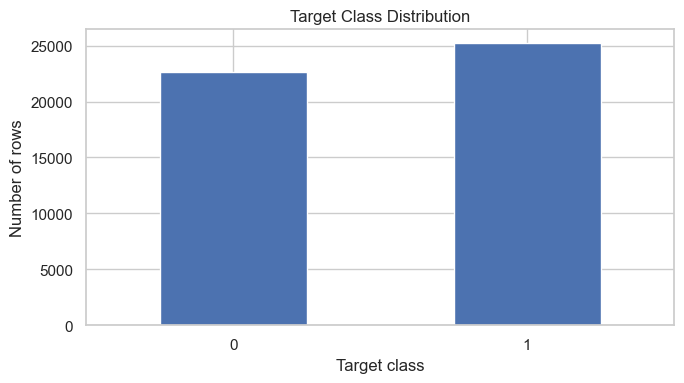

In [7]:
class_counts = y.value_counts().sort_index()
ax = class_counts.plot(kind="bar", figsize=(7, 4), rot=0)

ax.set_title("Target Class Distribution")
ax.set_xlabel("Target class")
ax.set_ylabel("Number of rows")

plt.tight_layout()
plt.show()

## 7. Split training data into train and validation sets

The supplied CSV is our development/training dataset. We reserve 20% of it for validation and use stratification to preserve the class proportions in both subsets.

The separate PCA test dataset will remain untouched until final evaluation. If you have a prescribed split from the project, keep using that split rather than creating a different one.

In [8]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training split:", X_train.shape, y_train.shape)
print("Validation split:", X_val.shape, y_val.shape)

print("\nTraining class proportions:")
display(y_train.value_counts(normalize=True).sort_index().round(3).to_frame("proportion"))

print("\nValidation class proportions:")
display(y_val.value_counts(normalize=True).sort_index().round(3).to_frame("proportion"))

Training split: (38300, 25) (38300,)
Validation split: (9575, 25) (9575,)

Training class proportions:


,proportion
target,
0,0.474
1,0.526



Validation class proportions:


,proportion
target,
0,0.474
1,0.526


## 8. Train a baseline Decision Tree

A Decision Tree learns a sequence of feature-based rules. For example, it may split on `PC01 <= threshold`, then split each resulting group again.

A fully grown tree can memorize training data, so we start with a constrained tree (`max_depth=5`) as a baseline. We will compare it with a tuned model later.

In [9]:
baseline_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=RANDOM_STATE,
    class_weight=None
)

baseline_model.fit(X_train, y_train)

baseline_train_pred = baseline_model.predict(X_train)
baseline_val_pred = baseline_model.predict(X_val)

print("Baseline tree depth:", baseline_model.get_depth())
print("Baseline number of leaves:", baseline_model.get_n_leaves())
print("Training accuracy:", round(accuracy_score(y_train, baseline_train_pred), 4))
print("Validation accuracy:", round(accuracy_score(y_val, baseline_val_pred), 4))

Baseline tree depth: 5
Baseline number of leaves: 28
Training accuracy: 0.9863
Validation accuracy: 0.986


## 9. Evaluation helper

This function calculates several complementary metrics:
- **Accuracy:** fraction of all predictions that are correct.
- **Precision:** among predicted positives, the fraction that are truly positive.
- **Recall:** among actual positives, the fraction detected by the model.
- **F1-score:** harmonic mean of precision and recall.
- **ROC-AUC:** ability to rank positive examples above negative examples.
- **PR-AUC / Average Precision:** summarizes the precision-recall trade-off and is especially useful with class imbalance.

For binary classification, the positive class is assumed to be label `1`. ROC-AUC and PR-AUC are calculated from predicted probabilities when available.

In [10]:
def evaluate_classifier(model, X_eval, y_eval, split_name="Validation"):
    y_pred = model.predict(X_eval)
    results = {
        "Split": split_name,
        "Accuracy": accuracy_score(y_eval, y_pred),
        "Precision": precision_score(y_eval, y_pred, average="binary", pos_label=1, zero_division=0),
        "Recall": recall_score(y_eval, y_pred, average="binary", pos_label=1, zero_division=0),
        "F1": f1_score(y_eval, y_pred, average="binary", pos_label=1, zero_division=0),
    }

    if hasattr(model, "predict_proba") and len(np.unique(y_eval)) == 2:
        positive_index = list(model.classes_).index(1) if 1 in model.classes_ else 1
        y_prob = model.predict_proba(X_eval)[:, positive_index]
        results["ROC_AUC"] = roc_auc_score(y_eval, y_prob)
        results["PR_AUC_AP"] = average_precision_score(y_eval, y_prob)
    else:
        results["ROC_AUC"] = np.nan
        results["PR_AUC_AP"] = np.nan

    return results

baseline_results = evaluate_classifier(baseline_model, X_val, y_val, "Baseline validation")
display(pd.DataFrame([baseline_results]).set_index("Split").round(4))

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC_AP
Split,,,,,,
Baseline validation,0.986,0.9934,0.98,0.9866,0.9884,0.9887


## 10. Tune hyperparameters with cross-validation

We tune tree complexity and split requirements. These settings control overfitting:
- `max_depth`: maximum depth of the tree.
- `min_samples_split`: minimum samples required to split a node.
- `min_samples_leaf`: minimum samples allowed in a leaf.
- `criterion`: impurity measure used to select splits.
- `class_weight`: optionally gives more weight to one class.

We use stratified 5-fold cross-validation on the training split. The scoring metric is **ROC-AUC** for binary classification. The validation set is not used during grid search.

In [11]:
param_grid = {
    "criterion": ["gini", "entropy", "log_loss"],
    "max_depth": [3, 5, 8, 12, None],
    "min_samples_split": [2, 10, 25],
    "min_samples_leaf": [1, 5, 10],
    "class_weight": [None, "balanced"],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True
)

grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_

print("Best cross-validation ROC-AUC:", round(grid_search.best_score_, 4))
print("\nBest hyperparameters:")
print(grid_search.best_params_)
print("\nBest tree depth:", best_model.get_depth())
print("Best tree leaves:", best_model.get_n_leaves())

Fitting 5 folds for each of 270 candidates, totalling 1350 fits
Best cross-validation ROC-AUC: 0.9967

Best hyperparameters:
{'class_weight': None, 'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 10, 'min_samples_split': 25}

Best tree depth: 5
Best tree leaves: 30


## 11. Compare baseline and tuned models

The tuned model is selected using cross-validation on the training split. We now evaluate both models on the same held-out validation split to see whether tuning improved generalization.

In [12]:
baseline_results = evaluate_classifier(baseline_model, X_val, y_val, "Baseline")
tuned_results = evaluate_classifier(best_model, X_val, y_val, "Tuned Decision Tree")

comparison_df = pd.DataFrame([baseline_results, tuned_results]).set_index("Split")
display(comparison_df.round(4))

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC_AP
Split,,,,,,
Baseline,0.9860,0.9934,0.9800,0.9866,0.9884,0.9887
Tuned Decision Tree,0.9853,0.9859,0.9861,0.9860,0.9966,0.9963


**Model Comparison Analysis**

Compared with the baseline, the tuned Decision Tree improved recall from 98.00% to 98.61%, ROC-AUC from 0.9884 to 0.9966, and PR-AUC (Average Precision) from 0.9887 to 0.9963. These improvements indicate better phishing detection at the selected threshold and stronger discrimination across classification thresholds. However, accuracy decreased slightly from 98.60% to 98.53%, precision decreased from 99.34% to 98.59%, and F1-score decreased from 98.66% to 98.60%. The tuned model is therefore promising when prioritizing phishing detection, although the final choice should consider the trade-off between missed phishing attacks and false alarms.

## 12. Final validation metrics and classification report

The classification report provides per-class precision, recall, F1-score, and support (number of true examples in each class). Review both classes rather than relying on a single aggregate score.

In [13]:
y_val_pred = best_model.predict(X_val)

print(classification_report(y_val, y_val_pred, digits=4, zero_division=0))

              precision    recall  f1-score   support

           0     0.9846    0.9844    0.9845      4537
           1     0.9859    0.9861    0.9860      5038

    accuracy                         0.9853      9575
   macro avg     0.9852    0.9852    0.9852      9575
weighted avg     0.9853    0.9853    0.9853      9575



**Classification Report Analysis**

The tuned Decision Tree achieved strong and balanced performance across both classes, with an overall accuracy of 98.53%. For the phishing class (Class 1), the model achieved 98.59% precision, 98.61% recall, and a 98.60% F1-score, indicating that it successfully identifies most phishing samples while maintaining a low false-alarm rate. Class 0 also showed consistent performance, with an F1-score of 98.45%. The macro-average F1-score of 98.52% confirms that the model performs well across both classes. Overall, these results demonstrate promising classification performance for the PhishGuard AI project.

## 13. Confusion matrix

The confusion matrix counts:
- **True negatives (TN):** class 0 correctly predicted as 0.
- **False positives (FP):** class 0 incorrectly predicted as 1.
- **False negatives (FN):** class 1 incorrectly predicted as 0.
- **True positives (TP):** class 1 correctly predicted as 1.

The impact of FP versus FN depends on the project. For example, in a fraud or security detection task, missing a positive case may be costly, so recall can be particularly important.

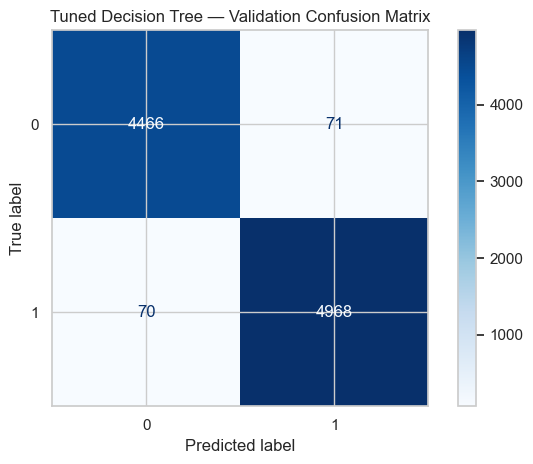

In [21]:
cm = confusion_matrix(y_val, y_val_pred, labels=best_model.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=best_model.classes_)

disp.plot(cmap="Blues", values_format="d")
plt.title("Tuned Decision Tree — Validation Confusion Matrix")

plt.tight_layout()
plt.show()

**Confusion Matrix Insights**

- **True Negatives (TN = 4,466):** The model correctly classified 4,466 legitimate URLs as legitimate.
- **False Positives (FP = 71):** The model incorrectly classified 71 legitimate URLs as phishing, resulting in a relatively low false alarm rate.
- **False Negatives (FN = 70):** The model incorrectly classified 70 phishing URLs as legitimate. These cases are particularly important because they represent potential security threats that could bypass detection.
- **True Positives (TP = 4,968):** The model correctly identified 4,968 phishing URLs, demonstrating strong phishing detection capability.

**Overall Interpretation:**

The model correctly classified **9,434 out of 9,575 samples**, achieving approximately **98.53% accuracy**. The false positive and false negative counts are nearly balanced, indicating that the model maintains a strong balance between detecting phishing URLs and avoiding false alarms. The phishing recall is approximately **98.61%**, meaning the model successfully detects the vast majority of phishing URLs, while the precision is approximately **98.59%**, indicating that most URLs flagged as phishing are actually malicious.

**Security Implication:** The low number of false negatives is particularly encouraging for PhishGuard AI, as it minimizes the number of phishing URLs incorrectly classified as legitimate. However, further reducing false negatives remains important to strengthen protection against phishing attacks.

## 14. ROC curve and Precision-Recall curve

The ROC curve plots true-positive rate against false-positive rate at different thresholds. The precision-recall curve shows the trade-off between precision and recall. These curves evaluate ranking performance rather than only the default class decision.

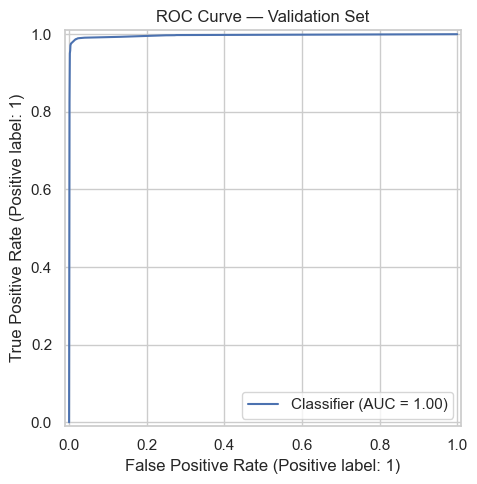

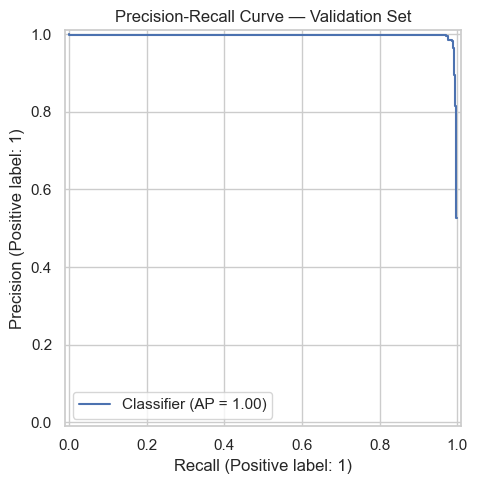

In [15]:
if len(best_model.classes_) == 2:
    positive_index = list(best_model.classes_).index(1) if 1 in best_model.classes_ else 1
    y_val_prob = best_model.predict_proba(X_val)[:, positive_index]

    fig, ax = plt.subplots(figsize=(7, 5))
    RocCurveDisplay.from_predictions(y_val, y_val_prob, ax=ax)
    ax.set_title("ROC Curve — Validation Set")
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(7, 5))
    PrecisionRecallDisplay.from_predictions(y_val, y_val_prob, ax=ax)
    ax.set_title("Precision-Recall Curve — Validation Set")
    plt.tight_layout()
    plt.show()
else:
    print("ROC and precision-recall curves in this section are configured for binary classification.")

## 15. Feature importance

Decision Trees calculate feature importance based on the total reduction in impurity contributed by each feature. With PCA data, `PC01`, `PC02`, etc. are principal components, not original input variables. Therefore, importance indicates which components the tree used most, not which original feature is individually important.

PCA components can combine information from many original features, so interpret component importance cautiously.

,PCA_Component,Importance
0,PC01,0.904066
5,PC06,0.032830
12,PC13,0.024266
6,PC07,0.012189
7,PC08,0.009323
22,PC23,0.006690
4,PC05,0.006642
3,PC04,0.001958
23,PC24,0.000966
20,PC21,0.000680


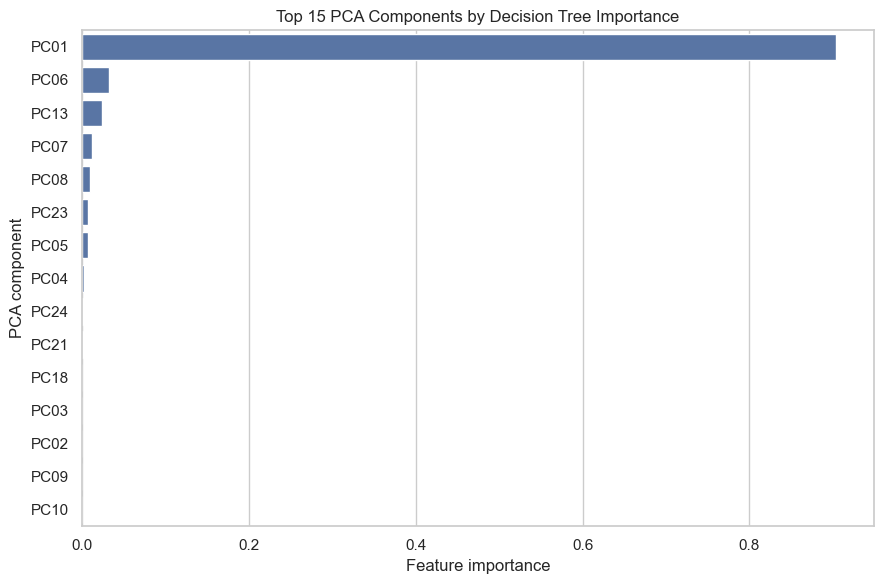

In [22]:
importance_df = pd.DataFrame({
    "PCA_Component": X.columns,
    "Importance": best_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance_df.head(15))

plt.figure(figsize=(9, 6))
sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="PCA_Component"
)
plt.title("Top 15 PCA Components by Decision Tree Importance")
plt.xlabel("Feature importance")
plt.ylabel("PCA component")

plt.tight_layout()
plt.show()

## 16. Visualize a simplified version of the tree

A fully tuned tree may be too large to interpret visually. This cell draws only the first few levels to show the types of splits the model learned. The displayed shallow tree is for interpretation; it is **not** a replacement for the selected model.

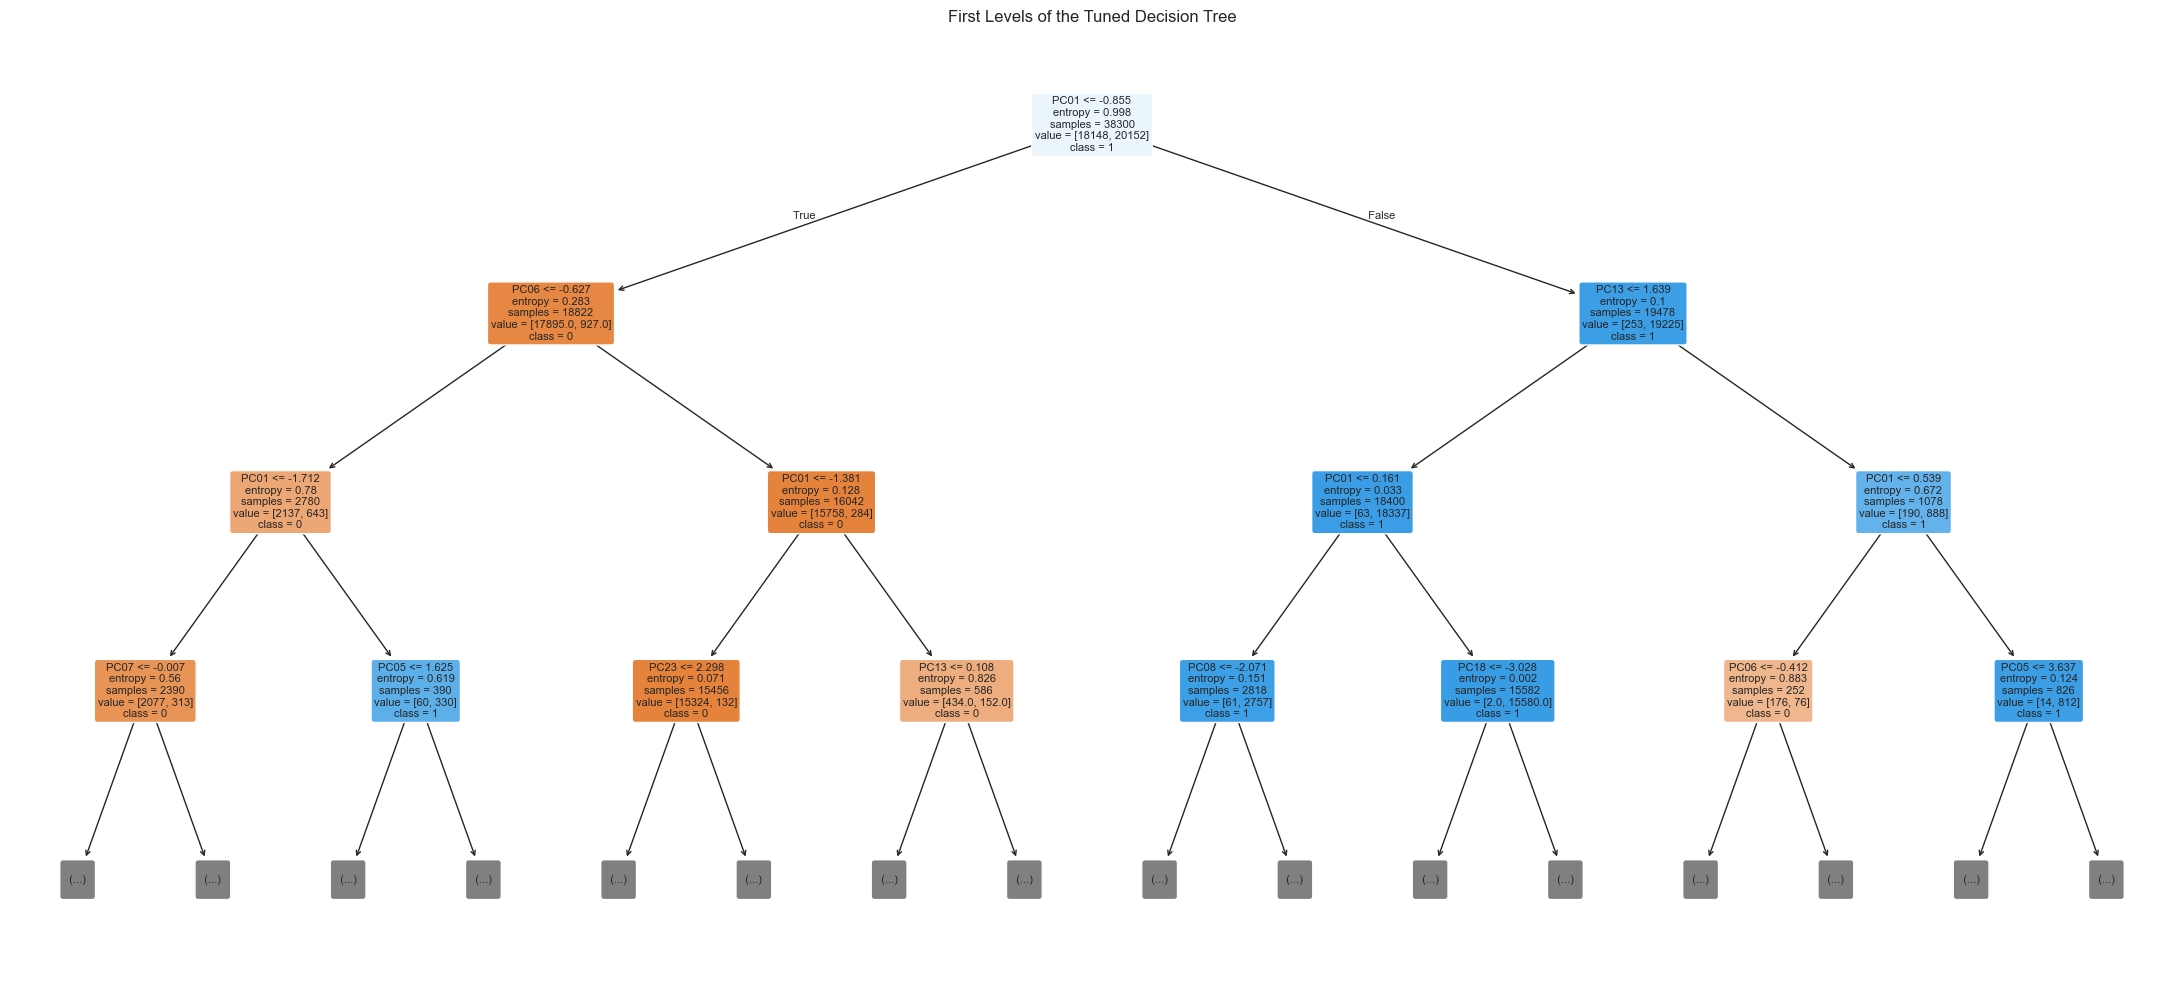

In [17]:
plt.figure(figsize=(22, 10))
plot_tree(
    best_model,
    feature_names=X.columns.tolist(),
    class_names=[str(c) for c in best_model.classes_],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)
plt.title("First Levels of the Tuned Decision Tree")
plt.tight_layout()
plt.show()

## 17. Export readable decision rules

This prints a text representation of the first few levels of the tree. Rules are based on PCA components, so they may be less interpretable in the original domain than rules based on original variables.

In [18]:
rules_text = export_text(
    best_model,
    feature_names=X.columns.tolist(),
    max_depth=3
)
print(rules_text)

|--- PC01 <= -0.86
|   |--- PC06 <= -0.63
|   |   |--- PC01 <= -1.71
|   |   |   |--- PC07 <= -0.01
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- PC07 >  -0.01
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- PC01 >  -1.71
|   |   |   |--- PC05 <= 1.63
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- PC05 >  1.63
|   |   |   |   |--- truncated branch of depth 2
|   |--- PC06 >  -0.63
|   |   |--- PC01 <= -1.38
|   |   |   |--- PC23 <= 2.30
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- PC23 >  2.30
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- PC01 >  -1.38
|   |   |   |--- PC13 <= 0.11
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- PC13 >  0.11
|   |   |   |   |--- truncated branch of depth 2
|--- PC01 >  -0.86
|   |--- PC13 <= 1.64
|   |   |--- PC01 <= 0.16
|   |   |   |--- PC08 <= -2.07
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- PC08 >  -2.07
|   |   |   |  

## 18. Evaluate on the separate PCA test dataset

This section runs only if `TEST_PATH` exists. The test file must use the same PCA component columns and the same component transformation/order as the training file.

Two common formats are supported:
1. **Labeled test data:** contains the `target` column. We report final test metrics.
2. **Unlabeled test data:** contains only PCA features. We save predictions, but cannot calculate performance metrics without true labels.

If the test file has a different feature set, the notebook stops with a clear error. Do not fit PCA separately on the test file; transform test data with the same PCA object used for training.

Test data loaded: (11970, 26)


,PC01,PC02,PC03,PC04,PC05,PC06,PC07,PC08,PC09,PC10,...,PC17,PC18,PC19,PC20,PC21,PC22,PC23,PC24,PC25,target
0,12.984398,3.110063,1.806657,5.262443,-1.394176,4.325276,1.252016,-0.779988,-1.083053,0.868971,...,-0.353845,-1.600950,-1.477043,-2.156816,-0.046751,-2.145054,0.860547,-0.379998,-0.934746,1
1,-3.090006,-1.633732,0.996983,2.338966,1.170254,0.250523,-0.400974,-0.061372,-2.276404,1.608350,...,0.028962,0.325779,0.075680,0.280514,-0.258337,0.726375,0.091159,-1.062848,-0.054180,0
2,8.522350,2.779248,-0.250621,6.961475,0.142579,-0.661627,-1.115884,-1.487677,1.045319,1.204239,...,0.774068,-0.271250,-1.432197,-0.884739,0.327659,-0.947347,0.246424,0.390603,-0.150181,1
3,13.187349,3.166163,1.894733,5.611153,-1.804267,4.247372,-0.230805,-0.402852,-1.303464,1.032871,...,-0.169819,-0.949935,-1.302161,-1.025951,0.377089,-2.009788,0.938501,0.326887,-0.610457,1
4,-3.065537,-1.578084,0.924381,2.296629,1.201918,0.408537,-0.295679,-0.223706,-2.177495,1.627050,...,0.440833,0.179244,0.054995,0.259994,0.159816,0.423182,-0.206764,-0.958095,-0.439095,0


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC_AP
Split,,,,,,
Final test,0.9891,0.988,0.9914,0.9897,0.9976,0.9977



Test classification report:
              precision    recall  f1-score   support

           0     0.9904    0.9866    0.9885      5672
           1     0.9880    0.9914    0.9897      6298

    accuracy                         0.9891     11970
   macro avg     0.9892    0.9890    0.9891     11970
weighted avg     0.9891    0.9891    0.9891     11970



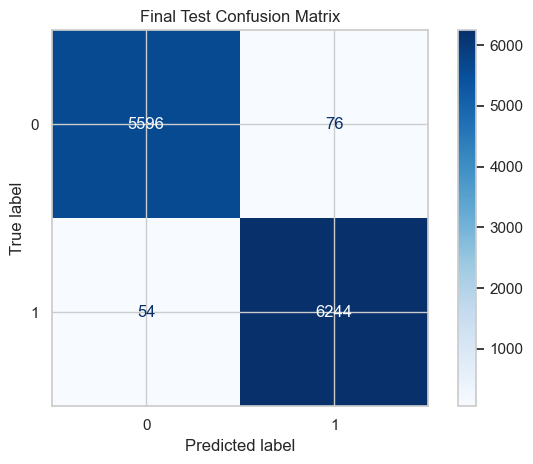

In [19]:
if TEST_PATH.exists():
    test_df = pd.read_csv(TEST_PATH)
    print("Test data loaded:", test_df.shape)
    display(test_df.head())

    missing_features = [col for col in X.columns if col not in test_df.columns]
    extra_features = [col for col in test_df.columns if col not in X.columns and col != TARGET_COLUMN]

    if missing_features:
        raise ValueError(
            "Test data is missing PCA feature columns: " + str(missing_features)
        )
    if extra_features:
        print("Note: extra non-target columns will be ignored:", extra_features)

    X_test = test_df[X.columns].copy()

    if X_test.select_dtypes(exclude=np.number).shape[1] > 0:
        raise ValueError("Test PCA features must all be numeric.")
    if X_test.isna().any().any():
        raise ValueError("Missing values found in test PCA features.")

    if TARGET_COLUMN in test_df.columns:
        y_test = test_df[TARGET_COLUMN].copy()
        if y_test.isna().any():
            raise ValueError("Missing target labels found in test data.")

        test_results = evaluate_classifier(best_model, X_test, y_test, "Final test")
        display(pd.DataFrame([test_results]).set_index("Split").round(4))

        y_test_pred = best_model.predict(X_test)
        print("\nTest classification report:")
        print(classification_report(y_test, y_test_pred, digits=4, zero_division=0))

        ConfusionMatrixDisplay.from_predictions(
            y_test,
            y_test_pred,
            labels=best_model.classes_,
            display_labels=best_model.classes_,
            cmap="Blues",
            values_format="d"
        )
        plt.title("Final Test Confusion Matrix")
        plt.tight_layout()
        plt.show()
    else:
        print("No target column found: generating predictions only.")
        y_test_pred = best_model.predict(X_test)
        predictions_df = pd.DataFrame({"prediction": y_test_pred})
        if hasattr(best_model, "predict_proba") and len(best_model.classes_) == 2:
            positive_index = list(best_model.classes_).index(1) if 1 in best_model.classes_ else 1
            predictions_df["probability_class_1"] = best_model.predict_proba(X_test)[:, positive_index]
        display(predictions_df.head())
        predictions_df.to_csv("decision_tree_test_predictions.csv", index=False)
        print("Saved predictions to decision_tree_test_predictions.csv")
else:
    print(f"Test file not found at: {TEST_PATH.resolve()}")
    print("Upload/copy your test PCA CSV next to this notebook, then update TEST_PATH and rerun this section.")

**Confusion Matrix Insights — Test Dataset**

- **True Negatives (TN = 5,596):** The model correctly classified 5,596 legitimate URLs as legitimate, demonstrating strong identification of benign URLs.

- **False Positives (FP = 76):** The model incorrectly classified 76 legitimate URLs as phishing. These false alarms may inconvenience users by flagging safe URLs as potentially malicious.

- **False Negatives (FN = 54):** The model incorrectly classified 54 phishing URLs as legitimate. These cases are particularly critical because they represent potential phishing threats that could bypass detection.

- **True Positives (TP = 6,244):** The model correctly identified 6,244 phishing URLs, demonstrating strong detection capability on unseen test data.

### Overall Interpretation

The model correctly classified **11,840 out of 11,970 test samples**, achieving an accuracy of approximately **98.91%**. It achieved a phishing precision of **98.80%** and a phishing recall of **99.14%**, indicating that it identifies the vast majority of phishing URLs while maintaining a low false alarm rate.

### Security Implications

The model produced only 54 false negatives compared with 6,244 correctly detected phishing URLs, which is encouraging for a phishing detection system. The high recall is especially important for PhishGuard AI because missed phishing URLs may expose users to malicious websites. Meanwhile, the relatively low number of false positives helps reduce unnecessary warnings for legitimate websites.

**Conclusion:** The test results demonstrate strong generalization performance, with high accuracy, precision, and recall on unseen data. However, continued evaluation of false negatives and precision-recall trade-offs is important before considering real-world deployment.

## 19. Save the selected model and experiment details

We save:
- The trained Decision Tree model (`decision_tree_pca_model.joblib`).
- The tuned hyperparameters and cross-validation score (`decision_tree_pca_results.txt`).
- The feature-importance table (`decision_tree_pca_feature_importance.csv`).

Keep the model together with the exact PCA transformation and feature order used to create the data. If the PCA transformer was fitted in a separate notebook, save and version that transformer too.

In [20]:
MODEL_PATH = "decision_tree_pca_model.joblib"
RESULTS_PATH = "decision_tree_pca_results.txt"
IMPORTANCE_PATH = "decision_tree_pca_feature_importance.csv"

joblib.dump(best_model, MODEL_PATH)
importance_df.to_csv(IMPORTANCE_PATH, index=False)

with open(RESULTS_PATH, "w", encoding="utf-8") as f:
    f.write("Decision Tree on PCA-transformed data\n")
    f.write("=" * 40 + "\n")
    f.write(f"Training rows: {len(X)}\n")
    f.write(f"Number of PCA features: {X.shape[1]}\n")
    f.write(f"Cross-validation ROC-AUC: {grid_search.best_score_:.6f}\n")
    f.write(f"Tree depth: {best_model.get_depth()}\n")
    f.write(f"Number of leaves: {best_model.get_n_leaves()}\n")
    f.write(f"Best parameters: {grid_search.best_params_}\n")
    f.write("\nValidation metrics:\n")
    f.write(comparison_df.round(6).to_string())
    f.write("\n")

print("Saved model:", os.path.abspath(MODEL_PATH))
print("Saved results:", os.path.abspath(RESULTS_PATH))
print("Saved feature importance:", os.path.abspath(IMPORTANCE_PATH))

Saved model: C:\Users\smata\DEPI Graduation Project\decision_tree_pca_model.joblib
Saved results: C:\Users\smata\DEPI Graduation Project\decision_tree_pca_results.txt
Saved feature importance: C:\Users\smata\DEPI Graduation Project\decision_tree_pca_feature_importance.csv
